#Importe de librerias necesarias

In [21]:
from astropy.io import fits
from astropy.table import Table
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

#Carga de datos y manipulación del archivo .FITS para trabajar con pandas

In [22]:
hdul = fits.open("gll_psc_v35.fit")
astropy_table = Table.read(hdul[1])  # Index 1 is usually the main catalog table

In [23]:
#Cambia el orden de bytes de los datos a nativo si es necesario
def _to_native_byteorder(arr: np.ndarray) -> np.ndarray:
    if arr.dtype.byteorder not in ("=", "|"):
        arr = arr.byteswap().view(arr.dtype.newbyteorder("="))
    return arr

#Convierte la tabla FITS a un DataFrame de Pandas, expandiendo las columnas multidimensionales en columnas separadas
def fits_table_to_full_dataframe(astropy_table: Table) -> pd.DataFrame:
    scalar_cols = []
    multidim_cols = []

    for name in astropy_table.colnames:
        col = astropy_table[name]

        if len(col.shape) <= 1:
            scalar_cols.append(name)
        else:
            multidim_cols.append(name)

    for name in astropy_table.colnames:
        data = np.asarray(astropy_table[name])
        if data.dtype.kind in "fiu":  # float, int, unsigned int
            astropy_table[name] = _to_native_byteorder(data)

    df = astropy_table[scalar_cols].to_pandas()

    for col in df.columns:
        if df[col].dtype == object and len(df) > 0 and isinstance(df[col].iloc[0], bytes):
            df[col] = df[col].str.decode("utf-8")

    expanded = {}
    for name in multidim_cols:
        arr = np.asarray(astropy_table[name])  # shape (n_rows, k [, ...])
        arr = arr.reshape(len(arr), -1)        # flatten any extra dims to 2D
        n_sub = arr.shape[1]
        for i in range(n_sub):
            expanded[f"{name}_{i}"] = arr[:, i]

    if expanded:
        df = pd.concat([df, pd.DataFrame(expanded, index=df.index)], axis=1)

    return df, multidim_cols, scalar_cols

#Exploración inicial y resumen del dataset

In [24]:
#Cuenta el número de valores vacíos en cada columna del DataFrame
def contar_vacios(df):
    conteo = df.isnull().sum()
    for col in df.select_dtypes(include='object').columns:
        vacios_texto = df[col].astype(str).str.strip().eq('').sum()
        conteo[col] = conteo[col] + vacios_texto
    return conteo.sort_values(ascending=False)

In [25]:
for name in astropy_table.colnames:
    col = astropy_table[name]
    if col.dtype.kind in "SO":
        print(name, col.dtype, repr(col[0]))

In [26]:
df, m_cols, s_cols = fits_table_to_full_dataframe(astropy_table)
rows, cols = df.shape
vacios = contar_vacios(df)

print("="*60)
print(f"Columnas multidimensionales: {len(m_cols)}")
print(f"Columnas unidimensionales: {len(s_cols)}")

print("="*60)
print(f"Columnas con valores nulos/vacios: ")
for col, count in vacios.items():
    if count > 0:
      print(f"{col}: {count}")

print("="*60)
print(f"Número de filas: {rows}")
print(f"Número de columnas: {cols}")
print("="*60)
print(f"Cantidad de columnas (Antes de expandir las multidim): {len(astropy_table.columns)}")
print(f"Cantidad de columnas: {len(df.columns)}")

Columnas multidimensionales: 7
Columnas unidimensionales: 72
Columnas con valores nulos/vacios: 
Unc_PLEC_Exp_Index: 7161
Extended_Source_Name: 7113
CLASS2: 7104
ASSOC_GAM3: 7095
ASSOC2: 7022
ASSOC_TEV: 6997
ASSOC_GAM2: 6993
ASSOC_GAM1: 6976
Unc_Flux_Band_0: 6646
Unc_Flux_Band_14: 5787
ASSOC_FHL: 5640
ASSOC_FGL: 4440
Unc_Flux_Band_2: 3859
Unc_Flux_Band_12: 3774
CLASS1: 2423
ASSOC1: 2423
Unc_Counterpart: 2423
RA_Counterpart: 2423
DEC_Counterpart: 2423
Unc_PLEC_EPeak: 2407
PLEC_EPeak: 2407
Unc_Flux_History_26: 1891
Unc_Flux_Band_10: 1880
Unc_Flux_History_24: 1823
Unc_Flux_History_20: 1770
Unc_Flux_History_22: 1692
Unc_Flux_History_18: 1685
Unc_Flux_History_16: 1606
Unc_Flux_History_0: 1517
Unc_Flux_History_6: 1513
Unc_Flux_History_8: 1510
Unc_Flux_History_4: 1490
Unc_Flux_History_10: 1474
Unc_Flux_History_12: 1471
Unc_Flux_History_2: 1436
Unc_Flux_History_14: 1429
Unc_Flux_Band_4: 1003
Unc_LP_EPeak: 904
LP_EPeak: 903
ASSOC_4FGL: 548
Unc_Flux_Band_8: 358
ASSOC_PROB_BAY: 278
Unc_Flux_Band_

C:\Users\jonha\AppData\Local\Temp\ipykernel_8248\1922918907.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [27]:
for col in sorted(df.columns):
    print(col)

ASSOC1
ASSOC2
ASSOC_4FGL
ASSOC_FGL
ASSOC_FHL
ASSOC_GAM1
ASSOC_GAM2
ASSOC_GAM3
ASSOC_PROB_BAY
ASSOC_PROB_LR
ASSOC_TEV
CLASS1
CLASS2
Conf_68_PosAng
Conf_68_SemiMajor
Conf_68_SemiMinor
Conf_95_PosAng
Conf_95_SemiMajor
Conf_95_SemiMinor
DEC_Counterpart
DEJ2000
DataRelease
Energy_Flux100
Extended_Source_Name
Flags
Flux1000
Flux_Band_0
Flux_Band_1
Flux_Band_2
Flux_Band_3
Flux_Band_4
Flux_Band_5
Flux_Band_6
Flux_Band_7
Flux_History_0
Flux_History_1
Flux_History_10
Flux_History_11
Flux_History_12
Flux_History_13
Flux_History_2
Flux_History_3
Flux_History_4
Flux_History_5
Flux_History_6
Flux_History_7
Flux_History_8
Flux_History_9
Flux_Peak
Frac_Variability
GLAT
GLON
LP_EPeak
LP_Flux_Density
LP_Index
LP_SigCurv
LP_beta
Npred
PLEC_EPeak
PLEC_Exp_Index
PLEC_ExpfactorS
PLEC_Flux_Density
PLEC_IndexS
PLEC_SigCurv
PL_Flux_Density
PL_Index
Peak_Interval
Pivot_Energy
RAJ2000
RA_Counterpart
ROI_num
Signif_Avg
Signif_Peak
Source_Name
SpectrumType
Sqrt_TS_Band_0
Sqrt_TS_Band_1
Sqrt_TS_Band_2
Sqrt_TS_Band_

In [28]:
def drop_columns(df, prefix):
    columns_to_drop = [col for col in df.columns if col.startswith(prefix)]
    df = df.drop(columns=columns_to_drop)
    return df

df = df.copy()
df = df.drop(columns=[
    "RAJ2000",
    "DEJ2000",
    "GLON",
    "GLAT",
    "ROI_num",
    "Extended_Source_Name",
    "Flags",
    "Source_Name",
    "CLASS2",#La dropee, pero hay 200 datos catalogados con solo esta clase, se puede retomar
])

df = drop_columns(df, "Conf_68")
df = drop_columns(df, "Conf_95")
df = drop_columns(df, "ASSOC")
df = drop_columns(df, "Unc")
df

,DataRelease,Signif_Avg,Pivot_Energy,Flux1000,Energy_Flux100,SpectrumType,PL_Flux_Density,PL_Index,LP_Flux_Density,LP_Index,...,Sqrt_TS_History_4,Sqrt_TS_History_5,Sqrt_TS_History_6,Sqrt_TS_History_7,Sqrt_TS_History_8,Sqrt_TS_History_9,Sqrt_TS_History_10,Sqrt_TS_History_11,Sqrt_TS_History_12,Sqrt_TS_History_13
0,1,8.492646,1917.715454,1.479606e-10,1.735209e-12,PowerLaw,4.284426e-14,2.247396,4.841716e-14,2.128013,...,2.024323,3.840539,3.172182,3.046058,0.000000,0.410956,1.517305,1.970749,2.060067,2.413337
1,2,5.681097,1379.882935,1.554103e-10,1.930614e-12,PowerLaw,9.782522e-14,2.330765,1.144858e-13,2.246985,...,1.580514,1.751642,2.230891,2.674823,4.963608,0.000000,0.811790,0.000000,2.932223,1.202639
2,3,4.197268,5989.263184,6.779151e-11,8.050527e-13,PowerLaw,2.134281e-15,1.856152,3.026530e-15,1.801879,...,1.231121,0.000000,1.708250,1.292136,0.464855,0.000000,1.811485,0.000000,0.000000,0.990755
3,1,5.523873,3218.100098,1.215529e-10,1.369124e-12,PowerLaw,1.136274e-14,2.155106,1.238304e-14,2.114229,...,0.000000,0.285321,1.893470,0.960601,2.011504,0.000000,0.062681,2.254160,3.200194,0.000000
4,1,24.497219,2065.146729,7.024454e-10,7.807578e-12,PowerLaw,1.690367e-13,2.081634,1.778363e-13,2.052470,...,7.208447,5.825856,6.605715,6.771310,10.708491,5.548215,4.809200,3.607690,6.028563,3.113805
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7190,1,18.289204,2930.842285,3.582566e-10,4.093997e-12,PowerLaw,4.240267e-14,1.928476,4.283416e-14,1.924309,...,5.292601,3.387712,3.265998,5.800932,5.238139,3.208765,5.406776,6.468659,4.950607,7.029840
7191,1,7.791155,581.708130,1.702680e-10,2.355763e-12,LogParabola,1.064677e-12,2.638458,1.327379e-12,2.466453,...,1.350941,2.293291,0.000000,3.164715,0.710967,0.480907,2.085095,2.797239,1.989603,1.611573
7192,3,5.150436,717.048584,7.982052e-11,1.116031e-12,LogParabola,2.954065e-13,2.714450,4.606104e-13,2.639918,...,1.267902,1.320493,0.182238,2.117821,1.572779,0.860041,0.000000,2.521716,1.734976,0.900663
7193,1,11.475555,1490.850708,2.448128e-10,1.752340e-12,LogParabola,1.005016e-13,2.094933,1.236632e-13,1.904424,...,3.418002,2.101004,3.087870,0.532565,2.358482,1.555077,2.835052,2.814638,3.999843,4.212942


In [29]:
df= df.drop(df[df["CLASS1"].str.strip() == ""].index)
df["CLASS1"] = df["CLASS1"].str.lower()
df["CLASS1"] = df["CLASS1"].str.strip()

df["CLASS1"] = df["CLASS1"].apply(lambda x : x if x in ["bll", "bcu", "fsrq"] else "other")

df= df.dropna()

df["BlazarDist"] = df["CLASS1"].apply(lambda x: 1 if x in ["bll", "bcu", "fsrq"] else 0)
print(df["CLASS1"].value_counts())
print(df["BlazarDist"].value_counts())
df


CLASS1
bll      1092
bcu       947
other     660
fsrq      218
Name: count, dtype: int64
BlazarDist
1    2257
0     660
Name: count, dtype: int64


,DataRelease,Signif_Avg,Pivot_Energy,Flux1000,Energy_Flux100,SpectrumType,PL_Flux_Density,PL_Index,LP_Flux_Density,LP_Index,...,Sqrt_TS_History_5,Sqrt_TS_History_6,Sqrt_TS_History_7,Sqrt_TS_History_8,Sqrt_TS_History_9,Sqrt_TS_History_10,Sqrt_TS_History_11,Sqrt_TS_History_12,Sqrt_TS_History_13,BlazarDist
4,1,24.497219,2065.146729,7.024454e-10,7.807578e-12,PowerLaw,1.690367e-13,2.081634,1.778363e-13,2.052470,...,5.825856,6.605715,6.771310,10.708491,5.548215,4.809200,3.607690,6.028563,3.113805,1
8,1,17.982479,2729.530029,3.126771e-10,3.260804e-12,LogParabola,3.982322e-14,1.781085,4.578294e-14,1.580971,...,3.358187,2.409387,3.989121,7.810023,7.284971,0.000000,1.575816,5.614650,6.524167,1
9,3,3.936026,4281.748047,7.768278e-11,8.967048e-13,PowerLaw,4.468771e-15,1.906426,5.982133e-15,1.763400,...,2.628741,0.000000,0.000000,1.470916,5.345222,2.793735,1.120369,0.000000,0.000000,1
10,1,16.672523,3402.819092,2.461732e-10,2.441939e-12,LogParabola,2.144947e-14,1.817964,2.620644e-14,1.599259,...,6.638917,3.212988,2.189012,3.340908,5.265853,5.866604,4.254807,5.912867,3.057119,1
11,1,6.391003,1996.203979,5.001652e-10,4.373159e-12,LogParabola,1.042069e-13,2.518880,1.426265e-13,2.641635,...,1.379536,0.355682,1.406976,0.852680,1.919586,3.419711,2.670889,1.953830,1.327101,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7188,2,8.577555,5153.450684,1.427346e-10,1.354165e-12,LogParabola,5.661042e-15,1.752499,9.833651e-15,1.577917,...,2.370328,0.196160,0.000000,1.093959,5.364328,4.830347,1.375243,3.231804,3.692428,1
7190,1,18.289204,2930.842285,3.582566e-10,4.093997e-12,PowerLaw,4.240267e-14,1.928476,4.283416e-14,1.924309,...,3.387712,3.265998,5.800932,5.238139,3.208765,5.406776,6.468659,4.950607,7.029840,1
7192,3,5.150436,717.048584,7.982052e-11,1.116031e-12,LogParabola,2.954065e-13,2.714450,4.606104e-13,2.639918,...,1.320493,0.182238,2.117821,1.572779,0.860041,0.000000,2.521716,1.734976,0.900663,1
7193,1,11.475555,1490.850708,2.448128e-10,1.752340e-12,LogParabola,1.005016e-13,2.094933,1.236632e-13,1.904424,...,2.101004,3.087870,0.532565,2.358482,1.555077,2.835052,2.814638,3.999843,4.212942,1


In [30]:
df = df[[
    "CLASS1",
    "BlazarDist",
    "Variability_Index",
    "Frac_Variability",
    "Energy_Flux100",
    #"Signif_Peak", Contiene valores infinitos, asi que aunque sea relevante, no se puede incluir en los modelos
    "SpectrumType",
    "LP_Index",
    #"Flux_Peak", Contiene valores infinitos, asi que aunque sea relevante, no se puede incluir en los modelos
    "LP_SigCurv",
    "PL_Index",
    "Pivot_Energy",
    "Flux_Band_0",
    "Flux_Band_1",
    "Flux_Band_2",
    "Flux_Band_3",
    "Flux_Band_4",
    "Flux_Band_5",
    "Flux_Band_6",
    "Flux_Band_7",
    "Flux_History_0",
    "Flux_History_1",
    "Flux_History_2",
    "Flux_History_3",
    "Flux_History_4",
    "Flux_History_5",
    "Flux_History_6",
    "Flux_History_7",
    "Flux_History_8",
    "Flux_History_9",
    "Flux_History_10",
    "Flux_History_11",
    "Flux_History_12",
    "Flux_History_13",
    "nuFnu_Band_0",
    "nuFnu_Band_1",
    "nuFnu_Band_2",
    "nuFnu_Band_3",
    "nuFnu_Band_4",
    "nuFnu_Band_5",
    "nuFnu_Band_6",
    "nuFnu_Band_7",
    ]]


In [31]:
df = pd.get_dummies(df, columns=["SpectrumType"], dtype=int)

#Análisis estadistico

In [32]:
df.describe()

,BlazarDist,Variability_Index,Frac_Variability,Energy_Flux100,LP_Index,LP_SigCurv,PL_Index,Pivot_Energy,Flux_Band_0,Flux_Band_1,...,nuFnu_Band_1,nuFnu_Band_2,nuFnu_Band_3,nuFnu_Band_4,nuFnu_Band_5,nuFnu_Band_6,nuFnu_Band_7,SpectrumType_LogParabola,SpectrumType_PLSuperExpCutoff,SpectrumType_PowerLaw
count,2917.000000,2917.000000,2917.000000,2.917000e+03,2917.000000,2917.000000,2917.000000,2917.000000,2.917000e+03,2.917000e+03,...,2.917000e+03,2.917000e+03,2.917000e+03,2.917000e+03,2.917000e+03,2.917000e+03,2.917000e+03,2917.000000,2917.000000,2917.000000
mean,0.773740,198.583862,0.285536,1.838155e-11,2.057549,3.868715,2.158828,3205.578613,1.443545e-08,1.185548e-08,...,2.951540e-12,4.096658e-12,4.242797e-12,2.626006e-12,1.146344e-12,7.312359e-13,3.442067e-13,0.469661,0.092904,0.437436
std,0.418481,2687.095459,0.360377,1.968681e-10,0.359194,8.968493,0.293193,4524.472168,1.294639e-07,1.195361e-07,...,3.022002e-11,5.038220e-11,5.536517e-11,2.990285e-11,5.634085e-12,3.071542e-12,2.393301e-12,0.499164,0.290347,0.496155
min,0.000000,2.884831,0.000000,3.638566e-13,0.850825,0.000000,1.110650,54.042686,3.325640e-20,1.615030e-20,...,4.035243e-24,4.584947e-22,5.481701e-21,7.927602e-22,2.888640e-24,8.413796e-26,3.256184e-28,0.000000,0.000000,0.000000
25%,1.000000,11.972379,0.000000,1.682945e-12,1.811595,1.297188,1.938777,1377.436646,2.248884e-11,1.371079e-10,...,3.538528e-14,1.960554e-13,2.512428e-13,2.143208e-13,9.366848e-14,7.595551e-17,6.038552e-18,0.000000,0.000000,0.000000
50%,1.000000,17.427940,0.190025,3.215707e-12,2.004672,2.267178,2.124728,2238.025635,1.134246e-09,1.740061e-09,...,4.364671e-13,5.230325e-13,5.154287e-13,4.275675e-13,2.849735e-13,1.374426e-13,8.276356e-17,0.000000,0.000000,0.000000
75%,1.000000,30.664347,0.445660,7.750432e-12,2.257015,3.747140,2.374219,3764.381836,8.877815e-09,4.979027e-09,...,1.237786e-12,1.465080e-12,1.380356e-12,1.093286e-12,6.838767e-13,4.934275e-13,1.350810e-13,1.000000,0.000000,1.000000
max,1.000000,96038.062500,3.661907,9.283040e-09,3.288755,253.718277,3.328158,173796.171875,5.384590e-06,5.609862e-06,...,1.425593e-09,2.409255e-09,2.559101e-09,1.384988e-09,2.284899e-10,9.536315e-11,7.890395e-11,1.000000,1.000000,1.000000


In [33]:
from sklearn.feature_selection import f_classif

X = df.select_dtypes(include=["number"])
X = X.drop(columns=["BlazarDist"])  # Exclude the target variable from features
y = df["CLASS1"]

f_scores, p_values = f_classif(X, y)
resultado = pd.DataFrame({"variable": X.columns, "f_score": f_scores, "p_value": p_values})
print(resultado.sort_values("f_score", ascending=False))

                         variable     f_score        p_value
38  SpectrumType_PLSuperExpCutoff  479.839807  2.400615e-253
5                        PL_Index  410.333121  2.577182e-222
3                        LP_Index  315.135298  3.452049e-177
1                Frac_Variability  190.191462  1.243078e-112
39          SpectrumType_PowerLaw  119.018041   1.040320e-72
4                      LP_SigCurv  103.241871   1.627901e-63
0               Variability_Index   27.760400   1.073319e-17
13                    Flux_Band_6   25.475006   2.898010e-16
35                   nuFnu_Band_6   25.131973   4.754398e-16
37       SpectrumType_LogParabola   16.522004   1.207554e-10
6                    Pivot_Energy   14.899423   1.261542e-09
34                   nuFnu_Band_5   12.584427   3.576455e-08
8                     Flux_Band_1   12.307590   5.333155e-08
30                   nuFnu_Band_1   12.153983   6.656555e-08
19                 Flux_History_4   11.992987   8.397093e-08
20                 Flux_

                               Variability_Index  Frac_Variability  \
Variability_Index                       1.000000          0.882026   
Frac_Variability                        0.882026          1.000000   
Energy_Flux100                          0.209073          0.117483   
LP_Index                               -0.048986          0.082891   
LP_SigCurv                              0.081735          0.024043   
PL_Index                               -0.075203          0.067064   
Pivot_Energy                           -0.235140         -0.269017   
Flux_Band_0                             0.141367          0.080889   
Flux_Band_1                             0.199087          0.144451   
Flux_Band_2                             0.193318          0.136412   
Flux_Band_3                             0.179961          0.104286   
Flux_Band_4                             0.203781          0.085221   
Flux_Band_5                             0.272492          0.110032   
Flux_Band_6         

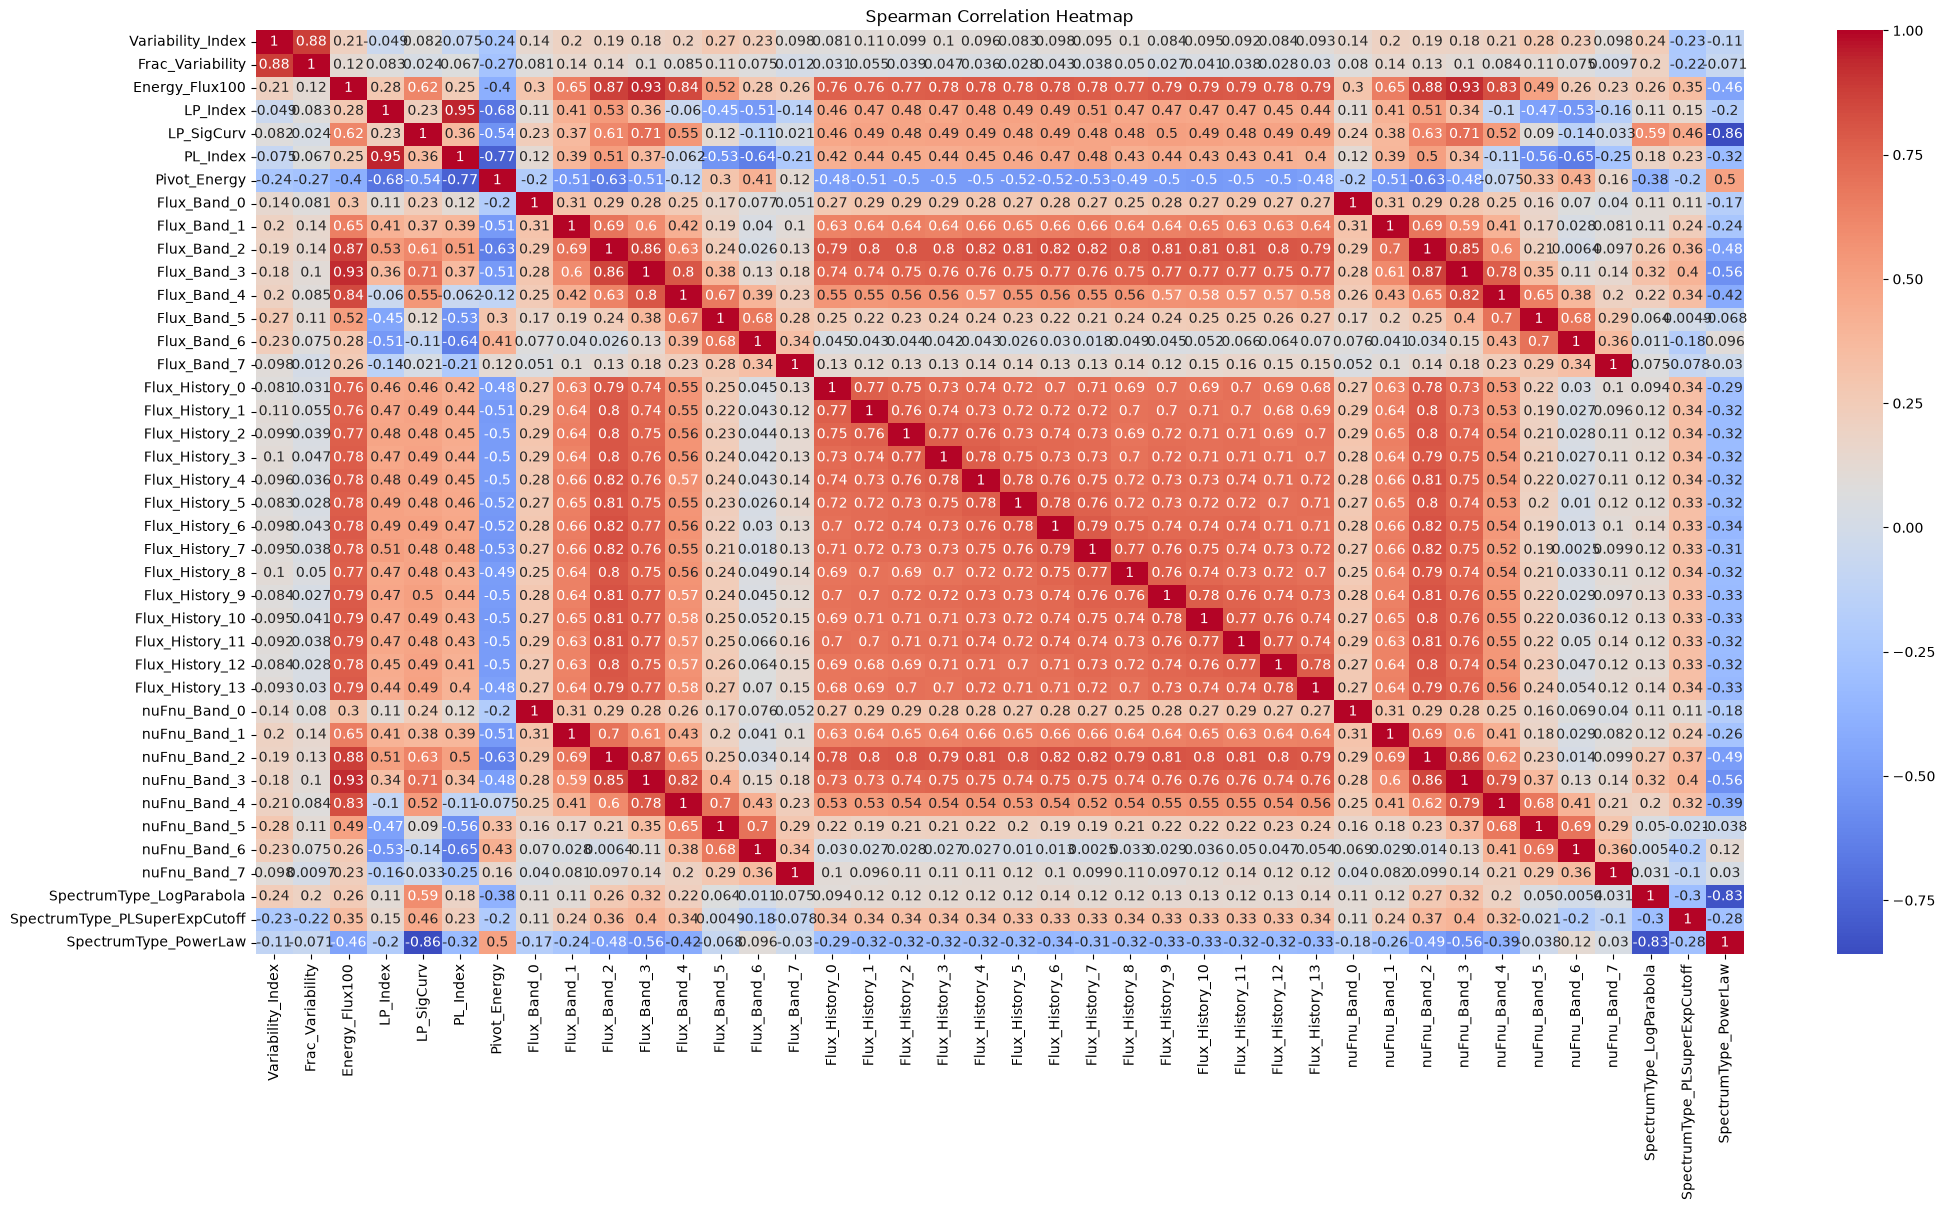

In [34]:
spearman_corr = X.corr(method='spearman')
print(spearman_corr)

plt.figure(figsize=(24, 12))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm')
plt.title("Spearman Correlation Heatmap")
plt.show()

#Redefinición del df con columnas relevantes

In [35]:
df = df[[
    "CLASS1",
    "BlazarDist",
    "Variability_Index",
    "Frac_Variability",
    "SpectrumType_LogParabola",
    "SpectrumType_PowerLaw",
    "SpectrumType_PLSuperExpCutoff",
    "Energy_Flux100",
    "LP_Index",
    "LP_SigCurv",
    "PL_Index",
    "Pivot_Energy",
    "Flux_Band_0",
    "Flux_Band_4",
    "Flux_Band_6",
    "Flux_Band_7",
    "nuFnu_Band_0",
    "nuFnu_Band_4",
    "nuFnu_Band_6",
    "nuFnu_Band_7",
    ]]

In [36]:
from sklearn.feature_selection import f_classif

X = df.select_dtypes(include=["number"])
X = X.drop(columns=["BlazarDist"])  # Exclude the target variable from features
y = df["CLASS1"]

f_scores, p_values = f_classif(X, y)
resultado = pd.DataFrame({"variable": X.columns, "f_score": f_scores, "p_value": p_values})
print(resultado.sort_values("f_score", ascending=False))

                         variable     f_score        p_value
4   SpectrumType_PLSuperExpCutoff  479.839807  2.400615e-253
8                        PL_Index  410.333121  2.577182e-222
6                        LP_Index  315.135298  3.452049e-177
1                Frac_Variability  190.191462  1.243078e-112
3           SpectrumType_PowerLaw  119.018041   1.040320e-72
7                      LP_SigCurv  103.241871   1.627901e-63
0               Variability_Index   27.760400   1.073319e-17
12                    Flux_Band_6   25.475006   2.898010e-16
16                   nuFnu_Band_6   25.131973   4.754398e-16
2        SpectrumType_LogParabola   16.522004   1.207554e-10
9                    Pivot_Energy   14.899423   1.261542e-09
5                  Energy_Flux100   10.649631   5.821890e-07
14                   nuFnu_Band_0   10.283379   9.863615e-07
10                    Flux_Band_0   10.197634   1.115886e-06
13                    Flux_Band_7    9.474223   3.157350e-06
17                   nuF

                               Variability_Index  Frac_Variability  \
Variability_Index                       1.000000          0.154844   
Frac_Variability                        0.154844          1.000000   
SpectrumType_LogParabola                0.008549          0.186040   
SpectrumType_PowerLaw                  -0.058020         -0.071236   
SpectrumType_PLSuperExpCutoff           0.084449         -0.198109   
Energy_Flux100                          0.096088         -0.025029   
LP_Index                                0.029251          0.097744   
LP_SigCurv                              0.133337         -0.063617   
PL_Index                                0.020515          0.124894   
Pivot_Energy                           -0.032838         -0.160193   
Flux_Band_0                             0.267565          0.005253   
Flux_Band_4                             0.059754         -0.027185   
Flux_Band_6                             0.088195          0.002079   
Flux_Band_7         

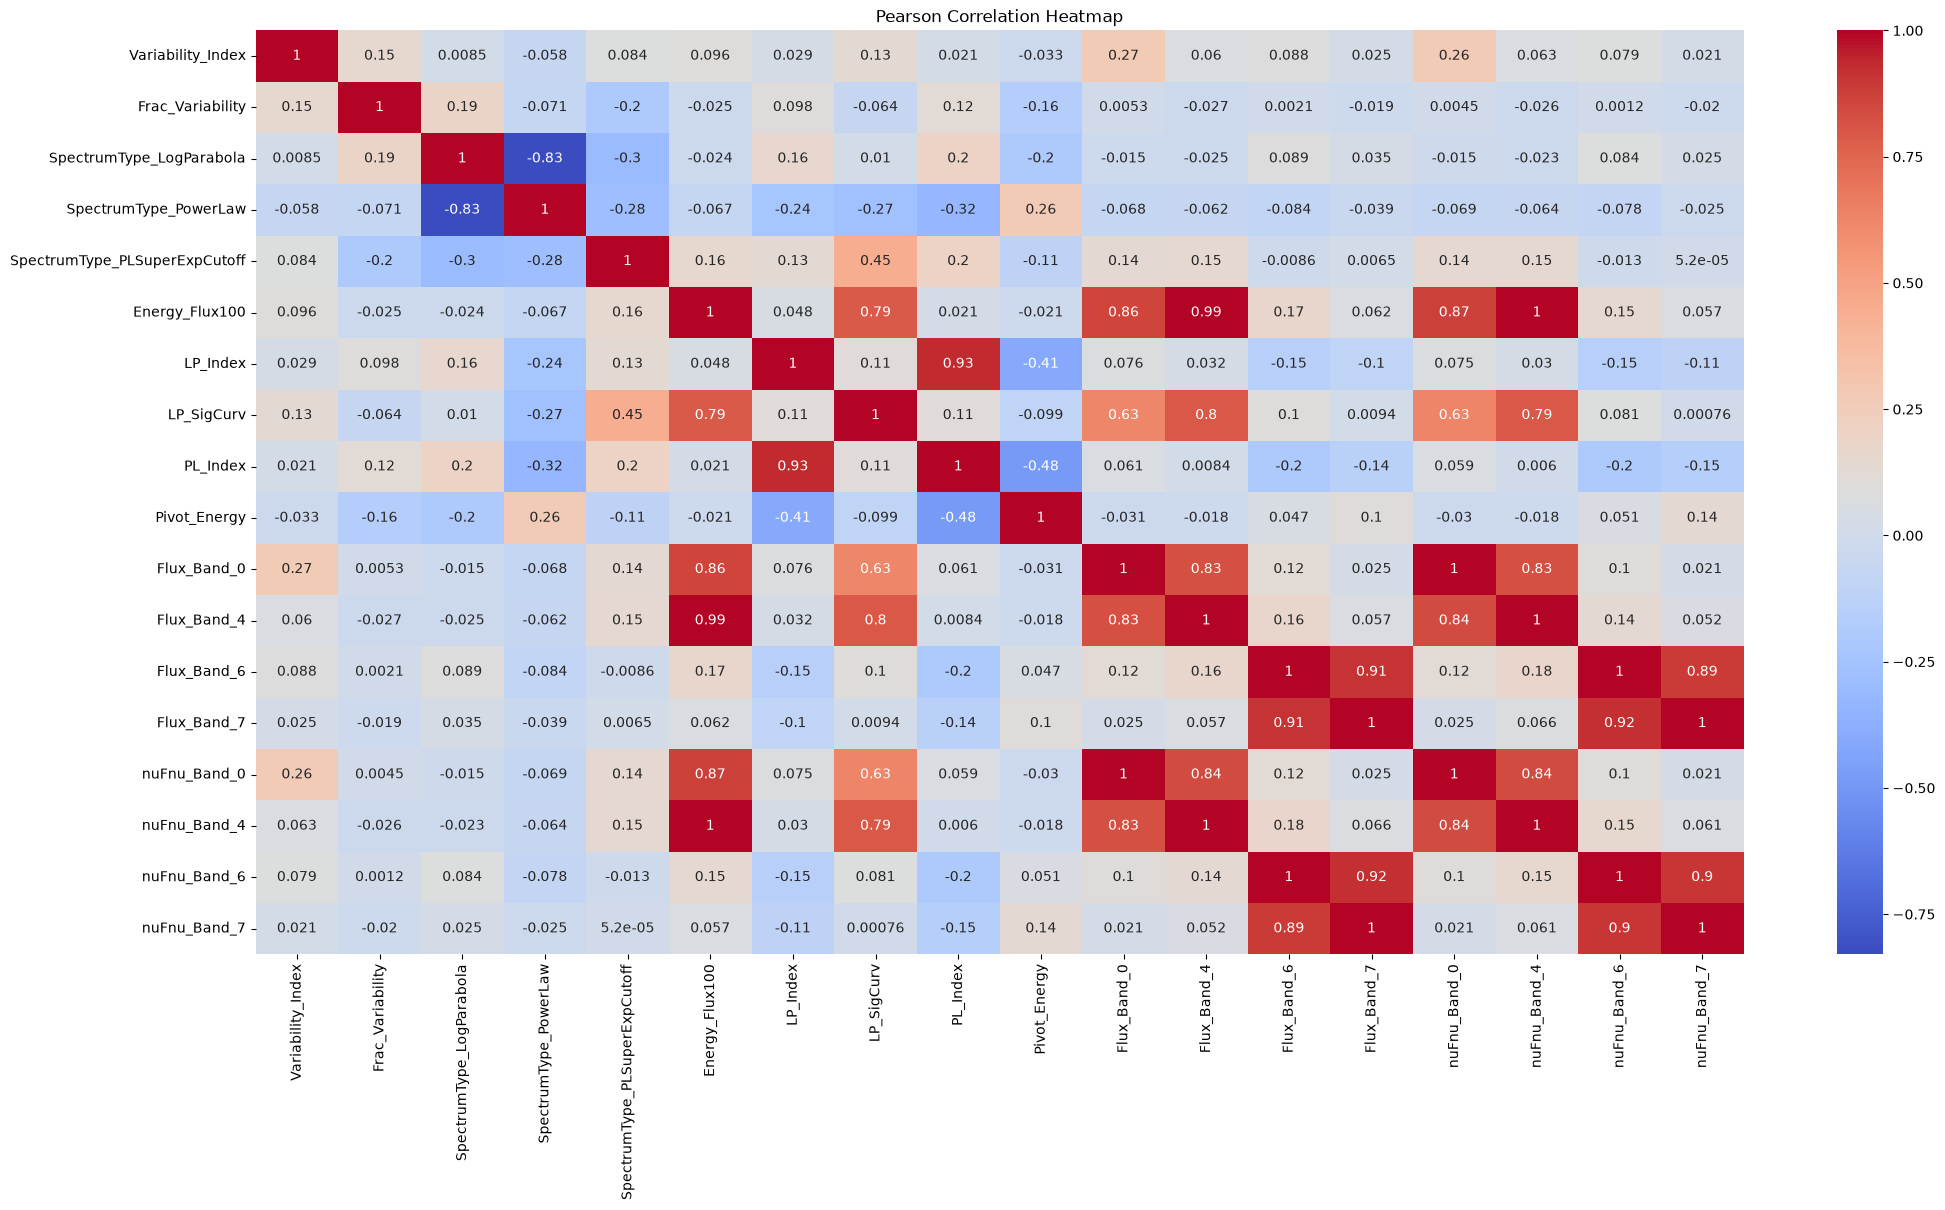

In [37]:
pearson_corr = X.corr(method='pearson')
print(pearson_corr)

plt.figure(figsize=(24, 12))
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm')
plt.title("Pearson Correlation Heatmap")
plt.show()

In [38]:
df["BlazarDist"] = df["CLASS1"].apply(lambda x: "blazar" if x in ["bll", "bcu", "fsrq"] else "non-blazar")

#Guardado del archivo

In [39]:
NOMBRE_ARCHIVO = "4FLG_Procesado_SMOTE.parquet"

if os.path.exists(NOMBRE_ARCHIVO):
    print(
        f"⚠️ El archivo '{NOMBRE_ARCHIVO}' ya existe. Procediendo a reemplazarlo..."
    )
    # Eliminamos el archivo viejo explícitamente para asegurar el reemplazo limpio
    os.remove(NOMBRE_ARCHIVO)
else:
    print(f"✨ Creando el archivo '{NOMBRE_ARCHIVO}' por primera vez...")

# Guardamos el nuevo DataFrame index=False para no meter columnas basura de índices
df.to_parquet(NOMBRE_ARCHIVO, index=False, compression="snappy")
print(f"✅ ¡Dataset guardado con éxito en '{NOMBRE_ARCHIVO}'!")

⚠️ El archivo '4FLG_Procesado_SMOTE.parquet' ya existe. Procediendo a reemplazarlo...
✅ ¡Dataset guardado con éxito en '4FLG_Procesado_SMOTE.parquet'!
